# fisherNN v4 — how good can a frozen closed-form body get?

**Where v3 left things.** A Fisher-discriminant (FD) body fit on task 0 and then frozen matches the
offline body (0.718 vs 0.716), and it still works when fit on 200 images, one class, or grayscale.
With a frozen body and an exact ridge readout, class-incremental accuracy at the end *equals* the joint
linear probe of that body. So the open question is no longer forgetting; it is the **ceiling of the
frozen body**, which sits about 10 points under joint backprop (0.824). A random ReLU projection did not
help, so a nonlinear readout of the pooled means is not the bottleneck.

**v4 asks**
1. **Does second-moment pooling help?** Readouts that pool E[h] *and* E[h²] per region from each
   layer's pre-pooling map. With a linear readout this spans the Gaussian Fisher-vector of each
   feature, and it adds the information each layer's 2×2 average pool throws away.
2. **How does FD compare with other cheap frozen bodies?** A Coates-style k-means layer (Coates, Lee &
   Ng 2011) and a data-free scattering transform (kymatio), under the same exact readout and data.
3. **Is the augmentation discarding colour?** v3's grayscale-fit body matched the colour one. Measure
   the chroma content of L1's responses and ablate the per-channel colour shift.
4. **SVHN body** (download retry), **class-incremental curves** with an exactness check, and a
   **replay baseline that is set up properly** (balanced mini-batches).

**Protocol (as v3):** 45k train / 5k validation / 10k test; bodies fit on task-0 images unless noted;
ridge λ picked on validation. Readout Gram matrices are accumulated in float64 (v3's float32
accumulation forced extra jitter at small λ). Results go to `results_v4.json`.

In [1]:
import math, copy, time, gc, json
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F

try:
    import ssl, certifi
    ssl._create_default_https_context = lambda: ssl.create_default_context(cafile=certifi.where())
except ImportError:
    pass

SMOKE = False
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
BETA, POOL = 0.1, 4
TASKS = [(0, 1), (2, 3), (4, 5), (6, 7), (8, 9)]
LAMS = (1e-5, 1e-4, 1e-3, 1e-2, 1e-1)
STAT_DEV = 'cpu'                 # readout statistics and solves (float64)
GRAM_DEV = 'cpu'                 # where each chunk's float64 Gram is computed. 'cpu' keeps GPU memory
                                 # flat; set to dev on a GPU with ≥8 GB and decent float64 throughput.

if SMOKE:
    WIDTHS, KM_K, VAL_N = (8, 16, 32), 64, 300
    SEEDS, RAND_SEEDS = (0, 1), (0,)
    JOINT_EPOCHS, REPLAY_EPOCHS, REPLAY_SIZES, CNN_WIDTHS = 2, 1, (5, 20), (16, 32, 64)
else:
    WIDTHS, KM_K, VAL_N = (32, 64, 128), 1600, 5000
    SEEDS, RAND_SEEDS = (0, 1, 2), (0,)          # random filters: 0.624 ± 0.005 in v3, one seed is enough
    JOINT_EPOCHS, REPLAY_EPOCHS, REPLAY_SIZES, CNN_WIDTHS = 15, 10, (50, 200), (64, 128, 256)

RUN = dict(probe=True, ci=True, color=True, svhn=True, bp=True)
OUT = dict(probe={}, ci={}, color={}, svhn={}, bp={},
           config=dict(widths=WIDTHS, km_k=KM_K, lams=LAMS, seeds=SEEDS, smoke=SMOKE))

## Data and augmentation
`AUG` reproduces v1–v3's augmentation exactly; Exp 3 changes `shared_shift`.

In [2]:
def load_cifar(root='./data'):
    import torchvision
    tr = torchvision.datasets.CIFAR10(root, train=True, download=True)
    te = torchvision.datasets.CIFAR10(root, train=False, download=True)
    f = lambda d: torch.tensor(d.data).permute(0, 3, 1, 2).float() / 255
    Xtr, Xte = f(tr), f(te)
    mean, std = Xtr.mean((0, 2, 3), keepdim=True), Xtr.std((0, 2, 3), keepdim=True)
    return (Xtr - mean) / std, torch.tensor(tr.targets), (Xte - mean) / std, torch.tensor(te.targets)

def load_synthetic(n_tr=2000, n_te=600, seed=0):
    """10 classes of smooth colour templates + structured noise + shifts. For code checks only."""
    g = torch.Generator().manual_seed(seed)
    T = F.interpolate(torch.randn(10, 3, 4, 4, generator=g), size=32, mode='bicubic', align_corners=False)
    def make(n):
        y = torch.randint(0, 10, (n,), generator=g)
        x = (T[y] * (0.5 + torch.rand(n, 1, 1, 1, generator=g))
             + 1.5 * F.interpolate(torch.randn(n, 3, 8, 8, generator=g), size=32, mode='bilinear',
                                   align_corners=False)
             + 0.5 * torch.randn(n, 3, 32, 32, generator=g))
        s = torch.randint(-3, 4, (n, 2), generator=g)
        return torch.stack([torch.roll(x[i], tuple(s[i].tolist()), (1, 2)) for i in range(n)]), y
    Xtr, Ytr = make(n_tr); Xte, Yte = make(n_te)
    mean, std = Xtr.mean((0, 2, 3), keepdim=True), Xtr.std((0, 2, 3), keepdim=True)
    return (Xtr - mean) / std, Ytr, (Xte - mean) / std, Yte

AUG = dict(scale=0.4, color_shift=0.3, shared_shift=False, noise=0.1, roll=1)

def augment(x, aug=None):
    a = AUG if aug is None else aug
    B = x.shape[0]
    x = x * (1 + a['scale'] * (torch.rand(B, 1, 1, 1, device=x.device) - 0.5))
    x = x + a['color_shift'] * torch.randn(B, 1 if a['shared_shift'] else 3, 1, 1, device=x.device)
    x = x + a['noise'] * torch.randn_like(x)
    r = a['roll']; dy, dx = torch.randint(-r, r + 1, (2,)).tolist()
    return torch.roll(x, (dy, dx), (2, 3))

Xall, Yall, Xte, Yte = load_synthetic() if SMOKE else load_cifar()
_perm = torch.randperm(len(Xall), generator=torch.Generator().manual_seed(1234))
Xva, Yva = Xall[_perm[:VAL_N]], Yall[_perm[:VAL_N]]
Xtr, Ytr = Xall[_perm[VAL_N:]], Yall[_perm[VAL_N:]]
del Xall, Yall

def task_data(cls):
    m = torch.isin(Ytr, torch.tensor(cls)); return Xtr[m], Ytr[m]

def free(tag=None):
    gc.collect()
    if torch.cuda.is_available():
        if tag: print(f'    [{tag}: peak GPU {torch.cuda.max_memory_allocated() / 2**30:.2f} GiB]')
        torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()

print(f'device {dev} | train {tuple(Xtr.shape)} | val {tuple(Xva.shape)} | test {tuple(Xte.shape)} '
      f'| smoke={SMOKE}')

Files already downloaded and verified
Files already downloaded and verified
device cuda | train (45000, 3, 32, 32) | val (5000, 3, 32, 32) | test (10000, 3, 32, 32) | smoke=False


## Bodies
Every body exposes `blocks(x) -> {name: spatial map}` and a batch size `bs`.
- **FD / random:** v3's layers. Blocks are the *pre-pooling* maps of L2 (16×16) and L3 (8×8), so a
  4×4 mean pool reproduces v3's features exactly and the second moment adds what the pool discarded.
- **k-means (Coates et al. 2011):** 6×6 patches, per-patch contrast normalization, ZCA whitening,
  k-means with K centroids, triangle activation max(0, mean_k d − d_k), stride 1 → 27×27 map,
  quadrant pooling. Fit on task-0 patches only, like the FD body.
- **Scattering (kymatio):** J=2, L=8 → 243 channels at 8×8. Data-free.

In [3]:
@torch.no_grad()
def gen_eig(ST, SW, k):
    ST, SW = ST.double().cpu(), SW.double().cpu()
    s, V = torch.linalg.eigh((SW + SW.T) / 2)
    s = s.clamp_min(s.max() * 1e-12)
    Linv = (V / s.sqrt()).T
    M = Linv @ ST @ Linv.T
    lam, U = torch.linalg.eigh((M + M.T) / 2)
    return lam.flip(0)[:k], Linv.T @ U.flip(1)[:, :k]

class FDLayer:
    def __init__(self, in_ch, k, ks, beta=BETA, eps=1e-3):
        self.ks, self.d = ks, in_ch * ks * ks
        self.k, self.beta, self.eps = min(k, self.d), beta, eps
        z = lambda *s: torch.zeros(*s, dtype=torch.float64, device=dev)
        self.n, self.s1, self.s2, self.nw, self.sw = 0.0, z(self.d), z(self.d, self.d), 0.0, z(self.d, self.d)
        self.W = self.mu = self.lam = None

    def patches(self, x):
        return F.unfold(x, self.ks, padding=self.ks // 2)

    @torch.no_grad()
    def observe(self, xa, xb, n_pos=64):
        pa, pb = self.patches(xa), self.patches(xb)
        idx = torch.randint(0, pa.shape[2], (n_pos,), device=dev)
        pa = pa[:, :, idx].transpose(1, 2).reshape(-1, self.d)
        pb = pb[:, :, idx].transpose(1, 2).reshape(-1, self.d)
        P, D = torch.cat([pa, pb]), pa - pb
        self.n += P.shape[0];  self.s1 += P.sum(0).double(); self.s2 += (P.T @ P).double()
        self.nw += D.shape[0]; self.sw += (D.T @ D).double()

    @torch.no_grad()
    def solve(self, random=False):
        mu = self.s1 / self.n
        ST = self.s2 / self.n - torch.outer(mu, mu)
        SW = self.sw / self.nw + self.beta * ST
        SW = SW + self.eps * SW.trace() / self.d * torch.eye(self.d, dtype=SW.dtype, device=dev)
        if random:
            W = torch.randn(self.d, self.k, dtype=torch.float64) / self.d ** 0.5
        else:
            self.lam, W = gen_eig(ST, SW, self.k)
        self.mu, self.W = mu.float(), W.float().to(dev)

    def pre(self, x):                          # [ReLU(z), ReLU(−z)] before the 2×2 average pool
        B, _, H, Wd = x.shape
        z = torch.einsum('bdl,dk->bkl', self.patches(x) - self.mu[None, :, None], self.W)
        z = z.reshape(B, self.k, H, Wd)
        return torch.cat([F.relu(z), F.relu(-z)], 1)

    def forward(self, x):
        return F.avg_pool2d(self.pre(x), 2)

class FDNet:
    def __init__(self, widths=WIDTHS, beta=BETA):
        k1, k2, k3 = widths
        self.layers = [FDLayer(3, k1, 5, beta), FDLayer(2 * k1, k2, 3, beta), FDLayer(2 * k2, k3, 3, beta)]
    def run(self, x, upto):
        for l in self.layers[:upto]: x = l.forward(x)
        return x

@torch.no_grad()
def fit_layers(net, X, bs=256, random=False, epochs=1, aug=None):
    for i, layer in enumerate(net.layers):
        for _ in range(epochs):
            for idx in torch.randperm(len(X)).split(bs):
                x = X[idx].to(dev)
                layer.observe(net.run(augment(x, aug), i), net.run(augment(x, aug), i))
        layer.solve(random)

class FDBody:
    bs = 500
    def __init__(self, X, seed=0, random=False, epochs=1, aug=None, widths=WIDTHS):
        torch.manual_seed(seed)
        self.net = FDNet(widths); fit_layers(self.net, X, random=random, epochs=epochs, aug=aug)
    @torch.no_grad()
    def blocks(self, x):
        out = {}
        for i, l in enumerate(self.net.layers):
            h = l.pre(x); x = F.avg_pool2d(h, 2)
            if i >= 1: out[f'L{i + 1}'] = h
        return out

class KMeansBody:
    bs = 50
    def __init__(self, X, seed=0, K=KM_K, ps=6, n_patches=400_000, iters=15, eps_norm=2.5e-3, eps_zca=0.1):
        # eps_norm = Coates's "+10" for 0-255 pixels, rescaled to unit-variance pixels
        self.K, self.ps, self.eps_norm = K, ps, eps_norm
        torch.manual_seed(seed)
        per = math.ceil(n_patches / len(X)); P = []
        for i in range(0, len(X), 500):
            p = F.unfold(X[i:i + 500].to(dev), ps)                              # (B, D, L)
            idx = torch.randint(0, p.shape[2], (p.shape[0], 1, per), device=dev).expand(-1, p.shape[1], -1)
            P.append(torch.gather(p, 2, idx).transpose(1, 2).reshape(-1, p.shape[1]))
        P = self._norm(torch.cat(P)[:n_patches])
        self.mz = P.mean(0)
        C = torch.cov((P - self.mz).T.double())
        e, V = torch.linalg.eigh(C)
        self.Wz = (V @ torch.diag((e.clamp_min(0) + eps_zca) ** -0.5) @ V.T).float()
        Z = (P - self.mz) @ self.Wz
        cent = Z[torch.randperm(len(Z), device=dev)[:K]].clone()
        for _ in range(iters):
            a = torch.cat([self._d2(Z[j:j + 50_000], cent).argmin(1) for j in range(0, len(Z), 50_000)])
            cnt = torch.bincount(a, minlength=K).float()
            sums = torch.zeros_like(cent).index_add_(0, a, Z)
            empty = cnt == 0
            cent = torch.where(empty[:, None], Z[torch.randint(0, len(Z), (K,), device=dev)],
                               sums / cnt.clamp_min(1)[:, None])
        self.cent = cent
        del P, Z
    def _norm(self, P):
        return (P - P.mean(1, keepdim=True)) / (P.var(1, keepdim=True) + self.eps_norm).sqrt()
    @staticmethod
    def _d2(Z, C):
        return (Z * Z).sum(1, keepdim=True) - 2 * Z @ C.T + (C * C).sum(1)
    @torch.no_grad()
    def blocks(self, x):
        B = x.shape[0]
        p = F.unfold(x, self.ps); L = p.shape[2]; s = int(round(L ** 0.5))
        z = (self._norm(p.transpose(1, 2).reshape(-1, p.shape[1])) - self.mz) @ self.Wz
        d = self._d2(z, self.cent).clamp_min(0).sqrt()
        f = F.relu(d.mean(1, keepdim=True) - d)                                   # triangle activation
        return {'km': f.reshape(B, s, s, self.K).permute(0, 3, 1, 2)}

class ScatBody:
    bs = 250
    def __init__(self, X=None, seed=0, J=2, L=8):
        # import the 2D frontend directly: kymatio.torch also imports the 3D code, which breaks on
        # recent SciPy (scipy.special.sph_harm was removed)
        from kymatio.scattering2d.frontend.torch_frontend import ScatteringTorch2D
        self.S = ScatteringTorch2D(J=J, shape=(32, 32), L=L).to(dev)
    @torch.no_grad()
    def blocks(self, x):
        s = self.S(x.contiguous())
        return {'scat': s.reshape(x.shape[0], -1, *s.shape[-2:])}

## Readouts
A readout spec picks blocks, a pooling grid, and whether to add the second moment E[h²] per region.
`RidgeReadout` is v3's exact ridge with float64 Gram accumulation, a wider λ grid and an in-place
solve for one-shot probes.

In [4]:
def featurize(bl, spec):
    g, out = spec.get('grid', POOL), []
    for b in spec['blocks']:
        h = bl[b]
        out.append(F.adaptive_avg_pool2d(h, g).flatten(1))
        if spec.get('mv'): out.append(F.adaptive_avg_pool2d(h * h, g).flatten(1))
    return torch.cat(out, 1)

FD_READOUTS = {
    'L3':          dict(blocks=('L3',)),
    'L2+L3':       dict(blocks=('L2', 'L3')),
    'L3 mv':       dict(blocks=('L3',), mv=True),
    'L2+L3 mv':    dict(blocks=('L2', 'L3'), mv=True),
}
KM_READOUTS = {
    'quadrants':    dict(blocks=('km',), grid=2),
    'quadrants mv': dict(blocks=('km',), grid=2, mv=True),
}
SCAT_READOUTS = {
    '4x4':    dict(blocks=('scat',)),
    '4x4 mv': dict(blocks=('scat',), mv=True),
}

def spd_solve(C, B, lam):
    """Solve (C + lam I) X = B for symmetric PSD C (lower triangle used); C is restored afterwards."""
    jitter = 0.0
    for _ in range(6):
        shift = lam + jitter
        C.diagonal().add_(shift)
        L, info = torch.linalg.cholesky_ex(C)
        C.diagonal().sub_(shift)
        if info.item() == 0:
            if jitter: print(f'    [spd_solve: λ={lam:g} needed extra jitter {jitter:.1e}]')
            return torch.cholesky_solve(B, L)
        jitter = max(10 * jitter, 1e-8)
    e, V = torch.linalg.eigh(C)
    return V @ ((V.T @ B) / (e.clamp_min(0) + lam)[:, None])

class RidgeReadout:
    def __init__(self, d, c=10, buf_mb=64):
        z = lambda *s: torch.zeros(*s, dtype=torch.float64, device=STAT_DEV)
        self.d, self.A, self.H, self.s, self.ys, self.n = d, z(d, d), z(d, c), z(d), z(c), 0.0
        self.c0, self.buf, self.nbuf = None, [], 0
        self.chunk = max(512, (buf_mb << 20) // (4 * d))
    def observe(self, phi, y):
        self.buf.append((phi.float(), y)); self.nbuf += len(phi)
        if self.nbuf >= self.chunk: self.flush()
    @torch.no_grad()
    def flush(self):
        if not self.buf: return
        phi = torch.cat([p for p, _ in self.buf]).to(GRAM_DEV, torch.float64)
        y = torch.cat([q for _, q in self.buf]).to(GRAM_DEV)
        self.buf, self.nbuf = [], 0
        if self.c0 is None: self.c0 = phi.mean(0).to(STAT_DEV)
        phi -= self.c0.to(GRAM_DEV)
        Y = F.one_hot(y, self.H.shape[1]).double()
        self.A += (phi.T @ phi).to(STAT_DEV); self.H += (phi.T @ Y).to(STAT_DEV)
        self.s += phi.sum(0).to(STAT_DEV);    self.ys += Y.sum(0).to(STAT_DEV); self.n += len(phi)
    @torch.no_grad()
    def solve(self, lams=LAMS, inplace=False, var_floor=1e-6):
        self.flush()
        m, yb = self.s / self.n, self.ys / self.n
        C = self.A if inplace else self.A.clone()
        C /= self.n; C.addr_(m, m, alpha=-1)
        var = C.diagonal().clone()
        sd = var.clamp_min(var_floor * var.clamp_min(0).mean() + 1e-12).sqrt()
        C /= sd[:, None]; C /= sd[None, :]
        Hc = (self.H / self.n - torch.outer(m, yb)) / sd[:, None]
        Ws = torch.stack([spd_solve(C, Hc, lam) / sd[:, None] for lam in lams])
        if inplace: self.A = None
        del C
        bs = yb[None] - torch.einsum('d,ldc->lc', m + self.c0, Ws)
        self.W, self.b = Ws.float().to(dev), bs.float().to(dev)
    def predict(self, phi):
        return torch.einsum('bd,ldc->lbc', phi, self.W) + self.b[:, None]

@torch.no_grad()
def eval_heads(body, specs, heads, X, Y, seen=tuple(range(10))):
    """Accuracy per readout per λ on images of `seen` classes: name -> (acc_all[L], acc_task0[L])."""
    m = torch.isin(Y, torch.tensor(seen)); X, Y = X[m], Y[m]
    t0 = torch.isin(Y, torch.tensor(TASKS[0]))
    mask = torch.full((10,), float('-inf'), device=dev); mask[list(seen)] = 0
    hits = {k: [torch.zeros(len(LAMS)), torch.zeros(len(LAMS))] for k in specs}
    for i in range(0, len(X), body.bs):
        bl = body.blocks(X[i:i + body.bs].to(dev)); y = Y[i:i + body.bs].to(dev); tm = t0[i:i + body.bs].to(dev)
        for k, spec in specs.items():
            ok = ((heads[k].predict(featurize(bl, spec)) + mask).argmax(2) == y).float()
            hits[k][0] += ok.sum(1).cpu(); hits[k][1] += ok[:, tm].sum(1).cpu()
    n0 = max(1, t0.sum().item())
    return {k: (h[0] / len(X), h[1] / n0) for k, h in hits.items()}

@torch.no_grad()
def probe(body, specs, tag=''):
    """Joint ridge probe on all 45k training images = final class-incremental accuracy of a frozen body."""
    heads = {}
    for i in range(0, len(Xtr), body.bs):
        bl = body.blocks(Xtr[i:i + body.bs].to(dev)); y = Ytr[i:i + body.bs].to(dev)
        for k, spec in specs.items():
            phi = featurize(bl, spec)
            if k not in heads: heads[k] = RidgeReadout(phi.shape[1])
            heads[k].observe(phi, y)
    for h in heads.values(): h.solve(inplace=True)
    va, te = eval_heads(body, specs, heads, Xva, Yva), eval_heads(body, specs, heads, Xte, Yte)
    res = {}
    for k in specs:
        j = int(va[k][0].argmax())
        res[k] = dict(test=te[k][0][j].item(), task0=te[k][1][j].item(), val=va[k][0][j].item(),
                      lam=LAMS[j], dim=heads[k].d, by_lam=te[k][0].tolist())
    if tag:
        print(f'  [{tag}] ' + ' | '.join(f'{k} {r["test"]:.3f} (d={r["dim"]}, λ={r["lam"]:g})'
                                         for k, r in res.items()), flush=True)
    return res

def mean_std(xs):
    a = np.array(xs, dtype=float); return a.mean(), (a.std(ddof=1) if len(a) > 1 else 0.0)

## Exp 1 — Bodies × readouts (final class-incremental accuracy = joint probe)

In [5]:
def try_scat():
    try:
        return ScatBody()
    except Exception as e:
        print(f'scattering unavailable ({type(e).__name__}: {str(e)[:80]}); `pip install kymatio` to include it')
        return None

BODIES = {   # name -> (constructor(seed), readouts, seeds)
    'FD':         (lambda s: FDBody(task_data(TASKS[0])[0], s), FD_READOUTS, SEEDS),
    'random':     (lambda s: FDBody(task_data(TASKS[0])[0], s, random=True), FD_READOUTS, RAND_SEEDS),
    'k-means':    (lambda s: KMeansBody(task_data(TASKS[0])[0], s), KM_READOUTS, SEEDS),
    'scattering': (lambda s: try_scat(), SCAT_READOUTS, (0,)),
}

if RUN['probe']:
    t0 = time.time()
    for name, (make, specs, seeds) in BODIES.items():
        for seed in seeds:
            ts = time.time()
            body = make(seed)
            if body is None: break
            tf = time.time() - ts
            res = probe(body, specs, tag=f'{name} s{seed}')
            for k, r in res.items():
                OUT['probe'].setdefault(name, {}).setdefault(k, []).append(r)
            body = None; free(f'{name} seed {seed}: fit {tf:.0f}s, total {time.time() - ts:.0f}s')
    print(f'[{time.time() - t0:.0f}s]\n')
    print(f'{"body":11s} {"readout":13s} {"dim":>6s} {"test (final CI)":>16s} {"task0":>7s}  λ')
    for name, d in OUT['probe'].items():
        for k, runs in d.items():
            m, s = mean_std([r['test'] for r in runs])
            print(f'{name:11s} {k:13s} {runs[0]["dim"]:6d} {m:9.3f} ± {s:.3f} '
                  f'{mean_std([r["task0"] for r in runs])[0]:7.3f}  {[r["lam"] for r in runs]}')

  [FD s0] L3 0.719 (d=4096, λ=0.01) | L2+L3 0.721 (d=6144, λ=0.1) | L3 mv 0.724 (d=8192, λ=0.1) | L2+L3 mv 0.738 (d=12288, λ=0.1)
    [FD seed 0: fit 8s, total 460s: peak GPU 1.09 GiB]
  [FD s1] L3 0.711 (d=4096, λ=0.0001) | L2+L3 0.716 (d=6144, λ=0.01) | L3 mv 0.721 (d=8192, λ=0.1) | L2+L3 mv 0.737 (d=12288, λ=0.1)
    [FD seed 1: fit 6s, total 303s: peak GPU 1.09 GiB]
  [FD s2] L3 0.723 (d=4096, λ=0.01) | L2+L3 0.728 (d=6144, λ=0.01) | L3 mv 0.726 (d=8192, λ=0.01) | L2+L3 mv 0.742 (d=12288, λ=0.1)
    [FD seed 2: fit 5s, total 296s: peak GPU 1.09 GiB]
  [random s0] L3 0.622 (d=4096, λ=0.001) | L2+L3 0.633 (d=6144, λ=0.01) | L3 mv 0.626 (d=8192, λ=0.01) | L2+L3 mv 0.646 (d=12288, λ=0.01)
    [random seed 0: fit 4s, total 264s: peak GPU 1.09 GiB]
  [k-means s0] quadrants 0.770 (d=6400, λ=0.0001) | quadrants mv 0.779 (d=12800, λ=0.001)
    [k-means seed 0: fit 2s, total 235s: peak GPU 1.13 GiB]
  [k-means s1] quadrants 0.763 (d=6400, λ=0.0001) | quadrants mv 0.779 (d=12800, λ=0.001)
   

## Exp 2 — Class-incremental curves for the best readout of FD and k-means
Same multi-λ harness as v3, now on any body. The last step should reproduce Exp 1's number for that
seed (same data, same λ choice): an exactness check of the frozen-body + exact-readout claim.

In [6]:
@torch.no_grad()
def run_ci(body, specs, tag=''):
    heads, hist, seen = {}, {k: [] for k in specs}, []
    for t, cls in enumerate(TASKS):
        seen += list(cls); X, Y = task_data(cls)
        for i in range(0, len(X), body.bs):
            bl = body.blocks(X[i:i + body.bs].to(dev)); y = Y[i:i + body.bs].to(dev)
            for k, spec in specs.items():
                phi = featurize(bl, spec)
                if k not in heads: heads[k] = RidgeReadout(phi.shape[1])
                heads[k].observe(phi, y)
        for h in heads.values(): h.solve()
        va = eval_heads(body, specs, heads, Xva, Yva, seen); te = eval_heads(body, specs, heads, Xte, Yte, seen)
        for k in specs:
            j = int(va[k][0].argmax())
            hist[k].append(dict(all=te[k][0][j].item(), task0=te[k][1][j].item(), lam=LAMS[j]))
        print(f'  [{tag}] task {t}: ' + ' | '.join(f'{k} {hist[k][-1]["all"]:.3f}' for k in specs), flush=True)
    return hist

def best_readout(name):
    d = OUT['probe'].get(name)
    return max(d, key=lambda k: mean_std([r['test'] for r in d[k]])[0]) if d else None

if RUN['ci']:
    t0 = time.time()
    for name in ('FD', 'k-means'):
        make, specs, _ = BODIES[name]
        k = best_readout(name) or list(specs)[-1]
        body = make(0)
        hist = run_ci(body, {k: specs[k]}, tag=f'{name} · {k}')[k]
        probe_val = OUT['probe'].get(name, {}).get(k, [{}])[0].get('test')
        OUT['ci'][f'{name} · {k}'] = dict(curve=[r['all'] for r in hist], task0=hist[-1]['task0'],
                                          final=hist[-1]['all'], avg_inc=float(np.mean([r['all'] for r in hist])),
                                          probe=probe_val)
        if probe_val is not None:
            print(f'    exactness check: final CI {hist[-1]["all"]:.4f} vs probe {probe_val:.4f}')
        body = None; free(name)
    print(f'[{time.time() - t0:.0f}s]')

  [FD · L2+L3 mv] task 0: L2+L3 mv 0.953
  [FD · L2+L3 mv] task 1: L2+L3 mv 0.850
  [FD · L2+L3 mv] task 2: L2+L3 mv 0.749
  [FD · L2+L3 mv] task 3: L2+L3 mv 0.741
  [FD · L2+L3 mv] task 4: L2+L3 mv 0.738
    exactness check: final CI 0.7381 vs probe 0.7381
    [FD: peak GPU 0.98 GiB]
  [k-means · quadrants mv] task 0: quadrants mv 0.963
  [k-means · quadrants mv] task 1: quadrants mv 0.881
  [k-means · quadrants mv] task 2: quadrants mv 0.788
  [k-means · quadrants mv] task 3: quadrants mv 0.773
  [k-means · quadrants mv] task 4: quadrants mv 0.779
    exactness check: final CI 0.7794 vs probe 0.7794
    [k-means: peak GPU 1.13 GiB]
[678s]


## Exp 3 — Is the augmentation throwing colour away?
(a) **Chroma share of L1 responses.** Split each 5×5×3 patch into luminance (channel mean, repeated)
and chroma (the rest); report each filter's response-variance share from chroma, for the FD body, a
body fit on grayscale images, and random filters.
(b) **Ablation.** Replace the independent per-channel colour shift (σ = 0.3 per channel) with a shared
brightness shift of the same size, so colour differences between views stop being "nuisance".

In [7]:
@torch.no_grad()
def chroma_share(layer, X, n_img=500):
    acc_c = acc_t = 0
    for i in range(0, min(n_img, len(X)), 100):
        p = layer.patches(X[i:i + 100].to(dev)).transpose(1, 2).reshape(-1, layer.d) - layer.mu
        pc = p.reshape(-1, 3, layer.d // 3); pc = (pc - pc.mean(1, keepdim=True)).reshape(-1, layer.d)
        acc_c = acc_c + ((pc @ layer.W) ** 2).sum(0); acc_t = acc_t + ((p @ layer.W) ** 2).sum(0)
    return (acc_c / acc_t).cpu()

if RUN['color']:
    t0 = time.time()
    X0 = task_data(TASKS[0])[0]
    gray = lambda X: X.mean(1, keepdim=True).expand(-1, 3, -1, -1).contiguous()
    bodies = {'FD (v1 aug)': FDBody(X0, 0), 'FD fit on grayscale': FDBody(gray(X0), 0),
              'FD shared shift': FDBody(X0, 0, aug=dict(AUG, shared_shift=True)),
              'random': FDBody(X0, 0, random=True)}
    print('(a) chroma share of L1 response variance (mean | fraction of filters > 0.5)')
    for name, b in bodies.items():
        cs = chroma_share(b.net.layers[0], X0)
        OUT['color'].setdefault('chroma', {})[name] = cs.tolist()
        print(f'    {name:22s} {cs.mean():.3f} | {(cs > 0.5).float().mean():.3f}')
    bodies = None; free()
    print('(b) shared vs independent colour shift, probe accuracy')
    specs = {k: FD_READOUTS[k] for k in ('L3', 'L2+L3 mv')}
    for seed in SEEDS:
        res = probe(FDBody(X0, seed, aug=dict(AUG, shared_shift=True)), specs, tag=f'shared shift s{seed}')
        for k, r in res.items(): OUT['color'].setdefault('shared_shift', {}).setdefault(k, []).append(r)
        free()
    if 'FD' in OUT['probe']:
        for k in specs:
            a = mean_std([r['test'] for r in OUT['color']['shared_shift'][k]])
            b = mean_std([r['test'] for r in OUT['probe']['FD'][k]])
            print(f'    {k:10s} shared {a[0]:.3f} ± {a[1]:.3f}   vs   independent (Exp 1) {b[0]:.3f} ± {b[1]:.3f}')
    print(f'[{time.time() - t0:.0f}s]')

(a) chroma share of L1 response variance (mean | fraction of filters > 0.5)
    FD (v1 aug)            0.545 | 0.531
    FD fit on grayscale    0.357 | 0.375
    FD shared shift        0.550 | 0.500
    random                 0.198 | 0.062
(b) shared vs independent colour shift, probe accuracy
  [shared shift s0] L3 0.702 (d=4096, λ=0.0001) | L2+L3 mv 0.720 (d=12288, λ=0.1)
  [shared shift s1] L3 0.691 (d=4096, λ=0.01) | L2+L3 mv 0.716 (d=12288, λ=0.1)
  [shared shift s2] L3 0.702 (d=4096, λ=0.0001) | L2+L3 mv 0.724 (d=12288, λ=0.1)
    L3         shared 0.698 ± 0.006   vs   independent (Exp 1) 0.717 ± 0.006
    L2+L3 mv   shared 0.720 ± 0.004   vs   independent (Exp 1) 0.739 ± 0.003
[640s]


## Exp 4 — FD body fit on SVHN (domain shift)
If the automatic download fails again, download `train_32x32.mat` from
http://ufldl.stanford.edu/housenumbers/ into `./data` and re-run this cell.

In [8]:
def load_svhn(n=10000, root='./data'):
    import torchvision, os
    have = os.path.exists(os.path.join(root, 'train_32x32.mat'))
    d = torchvision.datasets.SVHN(root, split='train', download=not have)
    X = torch.tensor(d.data[:n]).float() / 255
    return (X - X.mean((0, 2, 3), keepdim=True)) / X.std((0, 2, 3), keepdim=True)

if RUN['svhn']:
    try:
        Xs = load_svhn(n=10000 if not SMOKE else 500)
        specs = {k: FD_READOUTS[k] for k in ('L3', 'L2+L3 mv')}
        OUT['svhn'] = probe(FDBody(Xs, 0), specs, tag='FD fit on SVHN')
        free()
    except Exception as e:
        print(f'SVHN unavailable: {type(e).__name__}: {str(e)[:100]}')

SVHN unavailable: URLError: <urlopen error [WinError 10060] A connection attempt failed because the connected party did not prop


## Exp 5 — Backprop references: joint, and replay done properly
v3's replay concatenated the buffer into long epochs dominated by the current task. Here every step
draws a balanced batch (half current task, half buffer, as in experience replay), with
`REPLAY_EPOCHS` passes over each task's data and a class-balanced buffer.

In [9]:
class CNN(nn.Module):
    def __init__(self, w=CNN_WIDTHS):
        super().__init__()
        blk = lambda i, o, k: nn.Sequential(nn.Conv2d(i, o, k, padding=k // 2), nn.BatchNorm2d(o),
                                            nn.ReLU(), nn.AvgPool2d(2))
        self.body = nn.Sequential(blk(3, w[0], 5), blk(w[0], w[1], 3), blk(w[1], w[2], 3))
        self.head = nn.Linear(w[2] * 16, 10)
    def forward(self, x): return self.head(self.body(x).flatten(1))

@torch.no_grad()
def acc_seen(model, seen):
    m = torch.isin(Yte, torch.tensor(seen)); X, Y = Xte[m], Yte[m]
    t0 = torch.isin(Y, torch.tensor(TASKS[0]))
    mask = torch.full((10,), float('-inf'), device=dev); mask[seen] = 0
    pred = torch.cat([(model(X[i:i + 500].to(dev)) + mask).argmax(1).cpu() for i in range(0, len(X), 500)])
    ok = (pred == Y).float()
    return ok.mean().item(), ok[t0].mean().item()

def train_joint(epochs, bs=128, lr=1e-3, seed=0):
    torch.manual_seed(seed)
    model = CNN().to(dev); opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs * math.ceil(len(Xtr) / bs))
    model.train()
    for _ in range(epochs):
        for idx in torch.randperm(len(Xtr)).split(bs):
            loss = F.cross_entropy(model(augment(Xtr[idx].to(dev))), Ytr[idx].to(dev))
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    model.eval(); return model

def ci_replay(per_class, epochs=REPLAY_EPOCHS, bs=128, lr=5e-4, seed=0, tag=''):
    torch.manual_seed(seed)
    model = CNN().to(dev); opt = torch.optim.Adam(model.parameters(), lr=lr)
    bufX, bufY, seen, hist = Xtr[:0], Ytr[:0], [], []
    for t, cls in enumerate(TASKS):
        seen += list(cls); X, Y = task_data(cls)
        half = bs // 2 if len(bufX) else bs
        model.train()
        for _ in range(epochs):
            for idx in torch.randperm(len(X)).split(half):
                xb, yb = X[idx], Y[idx]
                if len(bufX):
                    j = torch.randint(0, len(bufX), (half,))
                    xb, yb = torch.cat([xb, bufX[j]]), torch.cat([yb, bufY[j]])
                loss = F.cross_entropy(model(augment(xb.to(dev))), yb.to(dev))
                opt.zero_grad(); loss.backward(); opt.step()
        model.eval()
        g = torch.Generator().manual_seed(seed * 100 + t)
        for c in cls:
            Xc = X[Y == c]; sel = torch.randperm(len(Xc), generator=g)[:per_class]
            bufX, bufY = torch.cat([bufX, Xc[sel]]), torch.cat([bufY, torch.full((len(sel),), c)])
        a, a0 = acc_seen(model, seen); hist.append(dict(all=a, task0=a0))
        print(f'  [{tag}] task {t}: all {a:.3f} | task0 {a0:.3f}', flush=True)
    return hist

if RUN['bp']:
    t0 = time.time()
    joint = train_joint(JOINT_EPOCHS)
    OUT['bp']['joint BP (upper bound)'] = dict(final=acc_seen(joint, list(range(10)))[0])
    print(f'  [joint BP] {JOINT_EPOCHS} epochs: {OUT["bp"]["joint BP (upper bound)"]["final"]:.3f}')
    del joint; free()
    for pc in REPLAY_SIZES:
        name = f'BP replay {pc * 10} imgs'
        h = ci_replay(pc, tag=name)
        OUT['bp'][name] = dict(final=h[-1]['all'], task0=h[-1]['task0'], curve=[r['all'] for r in h],
                               avg_inc=float(np.mean([r['all'] for r in h])))
        free()
    print(f'[{time.time() - t0:.0f}s]')

  [joint BP] 15 epochs: 0.824
  [BP replay 500 imgs] task 0: all 0.964 | task0 0.964
  [BP replay 500 imgs] task 1: all 0.706 | task0 0.551
  [BP replay 500 imgs] task 2: all 0.540 | task0 0.605
  [BP replay 500 imgs] task 3: all 0.445 | task0 0.511
  [BP replay 500 imgs] task 4: all 0.463 | task0 0.196
  [BP replay 2000 imgs] task 0: all 0.964 | task0 0.964
  [BP replay 2000 imgs] task 1: all 0.803 | task0 0.758
  [BP replay 2000 imgs] task 2: all 0.646 | task0 0.747
  [BP replay 2000 imgs] task 3: all 0.628 | task0 0.762
  [BP replay 2000 imgs] task 4: all 0.603 | task0 0.505
[265s]


## Summary
- **Q1:** does `mv` beat the same blocks without it on FD, and by more than on random filters?
- **Q2:** where does FD land against k-means and scattering at comparable readout dimension?
- **Q3:** does the shared colour shift raise FD's chroma share and accuracy?
- Frozen bodies store no images; replay stores the stated number.

method                                  final acc    dim seeds  stored imgs
joint BP (upper bound)               0.824              —     1  0
k-means · quadrants mv               0.780 ± 0.002  12800     3  0
k-means · quadrants                  0.766 ± 0.004   6400     3  0
FD · L2+L3 mv                        0.739 ± 0.003  12288     3  0
FD · L3 mv                           0.724 ± 0.003   8192     3  0
FD · L2+L3                           0.722 ± 0.006   6144     3  0
FD shared shift · L2+L3 mv           0.720 ± 0.004  12288     3  0
FD · L3                              0.717 ± 0.006   4096     3  0
FD shared shift · L3                 0.698 ± 0.006   4096     3  0
random · L2+L3 mv                    0.646          12288     1  0
random · L2+L3                       0.633           6144     1  0
random · L3 mv                       0.626           8192     1  0
random · L3                          0.622           4096     1  0
BP replay 2000 imgs                  0.603           

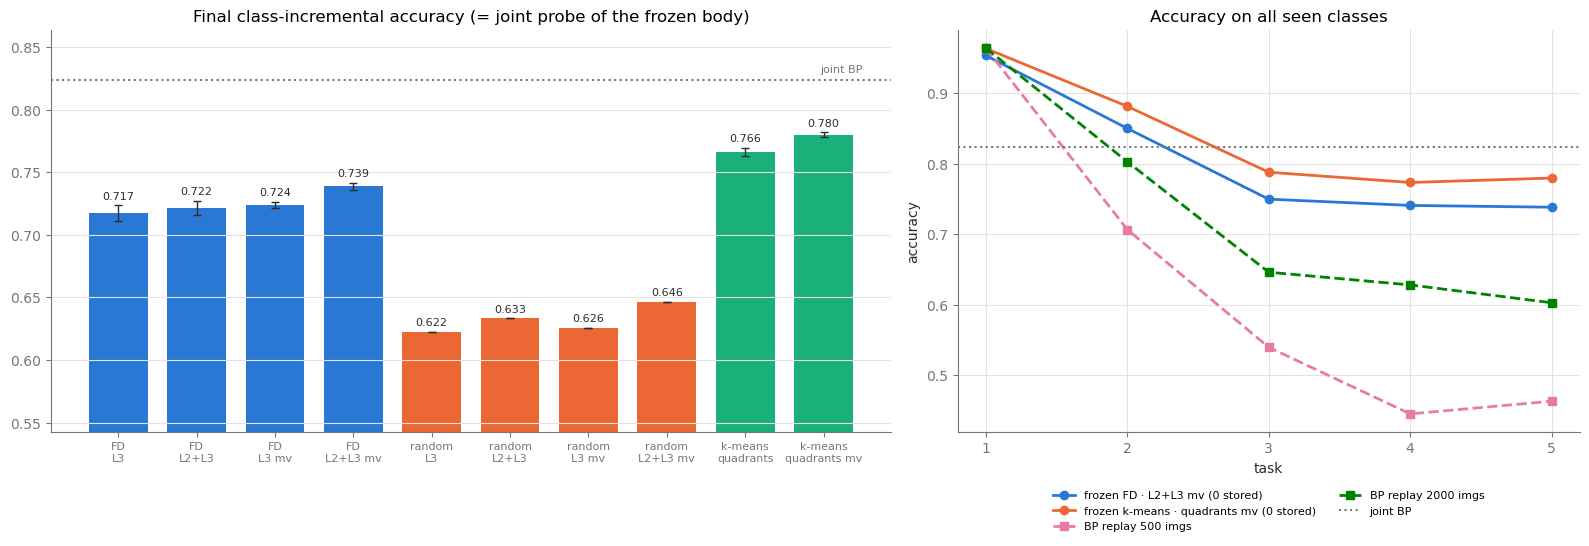

saved results_v4.json and summary_v4.png


In [10]:
import matplotlib.pyplot as plt

SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
INK, MUTED, GRID = '#2b2b29', '#77766f', '#e4e3de'
plt.rcParams.update({'axes.edgecolor': MUTED, 'axes.labelcolor': INK, 'xtick.color': MUTED,
                     'ytick.color': MUTED, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'font.size': 10})

rows = []
for name, d in OUT['probe'].items():
    for k, runs in d.items():
        rows.append((f'{name} · {k}', *mean_std([r['test'] for r in runs]), runs[0]['dim'], len(runs), 0))
for k, runs in OUT['color'].get('shared_shift', {}).items():
    rows.append((f'FD shared shift · {k}', *mean_std([r['test'] for r in runs]), runs[0]['dim'], len(runs), 0))
for k, r in OUT['svhn'].items():
    rows.append((f'FD fit on SVHN · {k}', r['test'], 0.0, r['dim'], 1, 0))
for name, r in OUT['bp'].items():
    rows.append((name, r['final'], 0.0, 0, 1, int(name.split()[2]) if 'replay' in name else 0))
print(f'{"method":32s} {"final acc":>16s} {"dim":>6s} seeds  stored imgs')
for name, m, s, dim, n, stored in sorted(rows, key=lambda r: -r[1]):
    print(f'{name:32s} {m:9.3f} {("± %.3f" % s) if n > 1 else " " * 7} {dim if dim else "—":>6} {n:5d}  {stored}')

fig, ax = plt.subplots(1, 2, figsize=(16, 5.6), gridspec_kw=dict(width_ratios=[1.35, 1]))

# (a) final accuracy per body × readout, mean ± sd; joint BP as reference line
labels, vals, errs, cols = [], [], [], []
for i, (name, d) in enumerate(OUT['probe'].items()):
    for k, runs in d.items():
        m, s = mean_std([r['test'] for r in runs])
        labels.append(f'{name}\n{k}'); vals.append(m); errs.append(s); cols.append(SERIES[i])
if vals:
    x = np.arange(len(vals))
    bars = ax[0].bar(x, vals, 0.75, yerr=errs, color=cols, capsize=3, error_kw=dict(ecolor=INK, lw=1))
    ax[0].bar_label(bars, fmt='%.3f', fontsize=8, color=INK, padding=3)
    if 'joint BP (upper bound)' in OUT['bp']:
        ax[0].axhline(OUT['bp']['joint BP (upper bound)']['final'], color=MUTED, lw=1.5, ls=':')
        ax[0].text(len(vals) - 0.5, OUT['bp']['joint BP (upper bound)']['final'] + 0.004,
                   'joint BP', ha='right', va='bottom', fontsize=8, color=MUTED)
    ax[0].set(title='Final class-incremental accuracy (= joint probe of the frozen body)', xticks=x,
              ylim=(max(0, min(vals) - 0.08), max(vals + [OUT['bp'].get('joint BP (upper bound)', {}).get('final', 0)]) + 0.04))
    ax[0].set_xticklabels(labels, fontsize=8)
    ax[0].grid(axis='x', visible=False)

# (b) class-incremental curves
steps = np.arange(1, len(TASKS) + 1)
for i, (name, r) in enumerate(OUT['ci'].items()):
    ax[1].plot(steps, r['curve'], color=SERIES[i], lw=2, marker='o', ms=6, label=f'frozen {name} (0 stored)')
for j, (name, r) in enumerate([(n, r) for n, r in OUT['bp'].items() if 'curve' in r]):
    ax[1].plot(steps, r['curve'], color=SERIES[4 + j], lw=2, ls='--', marker='s', ms=6, label=name)
if 'joint BP (upper bound)' in OUT['bp']:
    ax[1].axhline(OUT['bp']['joint BP (upper bound)']['final'], color=MUTED, lw=1.5, ls=':', label='joint BP')
ax[1].set(title='Accuracy on all seen classes', xlabel='task', ylabel='accuracy', xticks=steps)
ax[1].legend(fontsize=8, frameon=False, ncol=2, loc='upper center', bbox_to_anchor=(0.5, -0.12))

fig.tight_layout(); fig.savefig('summary_v4.png', dpi=130)
plt.show()

with open('results_v4.json', 'w') as f:
    json.dump(OUT, f, indent=1, default=str)
print('saved results_v4.json and summary_v4.png')